# 2.5b — C# — Calibration des probabilités : reliability diagrams, ECE, et pourquoi 0.87 n'est pas 87 % de chances

**Navigation** : [<< 2.5-Biais-Variance-CV-ROC](2.5-Biais-Variance-CV-ROC.ipynb) | [2.5c-Equite-Sous-Groupes →](2.5c-Equite-Sous-Groupes-CSharp.ipynb) | [Index](README.md) | [2.6-Clustering-KMeans-PCA >>](2.6-Clustering-KMeans-PCA.ipynb)

**Kernel** : .NET Interactive — C#

## Introduction

Le notebook 2.5 a montré comment évaluer un classifieur au-delà de l'accuracy : la **courbe ROC** et l'**AUC** mesurent la capacité du modèle à **ordonner** les exemples — quel exemple reçoit un score de classe 1 plus élevé. Mais l'AUC ne dit rien d'une question très concrète : quand le modèle affiche **0.87** pour un patient, a-t-il **87 % de chances** d'être positif ? Rien n'est moins sûr. Beaucoup de modèles produisent des **scores** qui ordonnent bien les exemples mais ne se comportent pas comme des **probabilités**. La calibration est la propriété qui fait coïncider les deux — et elle se diagnostique, se mesure et se répare.

Ce notebook s'intercale entre 2.5 et 2.6 : nous restons dans le supervisé probabiliste (même jeu de données `breast_cancer` et même découpage 70/30 que 2.5) en ajoutant l'outil qui manquait — lire un score comme une probabilité digne de ce nom.

### Objectifs d'apprentissage

À la fin de ce notebook, vous saurez :
1. Distinguer **score discriminant** (ordonner) et **probabilité calibrée** (quantifier), et diagnostiquer un modèle mal calibré.
2. Construire un **reliability diagram** from scratch : binning, confiance moyenne vs fréquence observée.
3. Chiffrer la calibration par l'**ECE** (Expected Calibration Error) et le **Brier score**.
4. Recalibrer un modèle avec le **Platt scaling** et la **régression isotonique** — et distinguer les conditions de conservation de l’ordre et les effets des ex æquo sur l’AUC.
5. Consommer des probabilités calibrées dans une **décision coût/bénéfice** (espérance de gain).

### Prérequis

- Notebook 2.1 (standardisation, train/test split, métriques).
- Notebook 2.3 (régression logistique, sigmoïde).
- Notebook 2.4 (forêts aléatoires).
- Notebook 2.5 (courbe ROC, AUC, seuil de décision).

> **Référence.** Niculescu-Mizil, A. & Caruana, R. (2005), *Predicting Good Probabilities With Supervised Learning*, ICML 2005. Sur huit problèmes de classification, la régression logistique, les réseaux de neurones et le bagging sortent globalement bien calibrés ; les méthodes à marge maximale (boosting, SVM) poussent la masse de probabilité **loin de 0 et 1**, vers le centre, d'où leur diagramme de fiabilité en forme de sigmoïde ; Naive Bayes fait exactement l'inverse, vers 0 et 1 ; les forêts aléatoires sont un cas « moins tranché » — bien calibrées sur certains problèmes, et ailleurs légèrement tirées vers le milieu, pour la raison même du bagging : moyenner des arbres de forte variance éloigne de 0 et 1 des prédictions qui devraient y être. C'est ce cadre que ce carnet met à l'épreuve, et nuance sur son propre jeu de données.


**Durée indicative** : 60–90 minutes avec les trois exercices. La classe 1 est bénigne ; les décisions coût/bénéfice sont une abstraction pédagogique.


**Politique de portage.** Les vrais modèles `StandardScaler`, `LogisticRegression`, `RandomForestClassifier` et `IsotonicRegression` sont appelés via Python.NET 3.1.0 (CPython compatible et `numpy`, `scikit-learn` installés). C# orchestre les cinq fits OOF et calcule binning, ECE, Brier, AUC, gains et figures SVG. NumPy fournit les mêmes données et indices seedés pour comparer les langages. Aucun carnet Python complet n’est encapsulé.


In [64]:
// CPython fournit les vrais estimateurs sklearn ; les métriques et figures restent natives.
#r "nuget: pythonnet, 3.1.0"
#load "../../../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using System.Text;
using System.Text.Json;
using System.Globalization;
using System.Security;
using Python.Runtime;
using Microsoft.DotNet.Interactive.Formatting;

public record CalibrationSvg(string Value);
Formatter.Register<CalibrationSvg>((value, writer) => writer.Write(value.Value), "image/svg+xml");
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.CurrentUICulture = CultureInfo.InvariantCulture;
if (!PythonEngine.IsInitialized)
{
    PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "sklearn");
    PythonEngine.BeginAllowThreads();
}

JsonElement Backend(string code, object config)
{
    // Le résultat JSON est détaché du scope avant libération sous le GIL.
    using (Py.GIL())
    {
        using var scope = Py.CreateScope();
        using var input = new PyString(JsonSerializer.Serialize(config));
        scope.Set("config_json", input);
        scope.Exec("import json, numpy as np\ncfg=json.loads(config_json)\n" + code);
        using var result = scope.Get("result_json");
        using var document = JsonDocument.Parse(result.As<string>());
        return document.RootElement.Clone();
    }
}

double[] Doubles(JsonElement x) => x.EnumerateArray().Select(v => v.GetDouble()).ToArray();
int[] Ints(JsonElement x) => x.EnumerateArray().Select(v => v.GetInt32()).ToArray();
double[][] Matrix(JsonElement x) => x.EnumerateArray().Select(Doubles).ToArray();
var dataset = Backend(@"
import sys, sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold
cancer=load_breast_cancer()
X_train,X_test,y_train,y_test=train_test_split(cancer.data[:,[2,9]], cancer.target,
    test_size=.3, random_state=42, stratify=cancer.target)
folds=[{'train':a.tolist(),'valid':b.tolist()} for a,b in StratifiedKFold(5).split(X_train,y_train)]
result_json=json.dumps(dict(X_train=X_train.tolist(),X_test=X_test.tolist(),
    y_train=y_train.tolist(),y_test=y_test.tolist(),folds=folds,
    versions=dict(python=sys.version.split()[0],numpy=np.__version__,sklearn=sklearn.__version__)))
", new { });
var XTrain = Matrix(dataset.GetProperty("X_train"));
var XTest = Matrix(dataset.GetProperty("X_test"));
var yTrain = Ints(dataset.GetProperty("y_train"));
var yTest = Ints(dataset.GetProperty("y_test"));
Console.WriteLine($".NET {Environment.Version} ; Python.NET {typeof(PythonEngine).Assembly.GetName().Version}");
Console.WriteLine(dataset.GetProperty("versions"));
Console.WriteLine("Mesures : mean perimeter ; mean fractal dimension");
Console.WriteLine($"Entraînement : {yTrain.Length} lignes | Test : {yTest.Length} lignes");
Console.WriteLine($"Taux de base (classe 1, bénin) : {yTest.Average():F3}");


Installing Packages pythonnet

.NET 10.0.13 ; Python.NET 3.1.0.0


{"python": "3.13.16", "numpy": "2.4.2", "sklearn": "1.9.1"}


Mesures : mean perimeter ; mean fractal dimension


Entraînement : 398 lignes | Test : 171 lignes


Taux de base (classe 1, bénin) : 0.626


## 1. Pourquoi calibrer ? Le modèle qui dit 0.87 a-t-il raison 87 % du temps ?

Un classifieur binaire produit pour chaque exemple un score dans [0, 1]. Deux questions distinctes s'y cachent :

- **Ordonner** (*discrimination*) : le score de classe 1 du patient A (0.91) classe-t-il correctement cet exemple devant B (0.12) ? L’AUC mesure le classement ; l’accuracy évalue les décisions à un seuil donné. Ici, classe 1 signifie **bénin**, pas risque de malignité.
- **Quantifier** (*calibration*) : parmi tous les patients qui reçoivent le score 0.87, quelle proportion est réellement positive ? Si la réponse est « 87 % », le modèle est **calibré** : son score s'interprète littéralement comme une probabilité.

Un modèle peut ordonner correctement et quantifier très mal. Le mécanisme le plus courant est celui des **ensembles** : une forêt aléatoire moyenne les probabilités estimées dans les feuilles de ses arbres. Si les feuilles sont pures, chaque arbre rend 0 ou 1 et la moyenne sur cent arbres est un multiple de 1/100 ; ce cas ne vaut pas pour toute forêt ni tout jeu de données. Le score moyen reste proche du taux de base, et la distribution est **bi-modale** : ici **76 %** des scores de test tombent hors de [0.1, 0.9], le bin le plus peuplé étant celui des scores ~0.98. La régression logistique, elle, optimise une log-vraisemblance et produit des scores étalés sur tout l'intervalle.

Ce que le papier de référence établit n'est pourtant pas « les arbres écrasent leurs scores vers 0 et 1 » : ce sont les méthodes à **marge maximale** qui sont poussées **loin de 0 et 1**, Naive Bayes qui l'est vers 0 et 1, et les ensembles par moyennage (bagging, forêts aléatoires) qui sont tirés **vers le milieu** — moyenner des arbres de forte variance rend les valeurs extrêmes difficiles à atteindre. Notre mesure décrit donc **ce jeu-ci**, pas une loi générale : avec les deux mesures retenues la majorité des patients reste facile à trancher, d'où les scores extrêmes ; mais dans la zone médiane, la forêt **sous-estime** sa confiance dans quatre bins sur cinq (0.55, 0.65, 0.75, 0.85), le seul écart de sens inverse ne portant que sur quatre exemples. Distribution marginale écrasée aux bords et sous-confiance au milieu coexistent — ce constat expérimental ne suffit pas à identifier un mécanisme causal.

**Un choix de protocole, et pourquoi.** Sur les 30 variables du jeu (notebook 2.5), le problème est si bien séparé que même la forêt reste quasi calibrée : ses scores extrêmes sont *mérités*. Le défaut de calibration naît quand les classes se **chevauchent** et qu'un modèle flexible **mémorise** le bruit. Nous travaillons donc avec **deux mesures seulement** — le périmètre moyen et la dimension fractale moyenne, deux variables de pouvoirs discriminants différents — pour une expérience pédagogique réduite à deux variables. La confrontation :

| Modèle | Discrimination attendue | Calibration attendue |
|---|---|---|
| `LogisticRegression(max_iter=1000)` (sur mesures standardisées) | bonne | à mesurer sur ce test |
| `RandomForestClassifier(n_estimators=100)` | bonne, du même ordre | sur ce tirage, ECE ≈ 2× celle de la régression logistique ; cela ne généralise pas à toute forêt |

L'objectif n'est pas de les départager en accuracy : c'est de rendre visible le **second axe**, celui que l'AUC ne voit pas.


Modèle               moyenne  prédits 1  part dans [0.1,0.9]


LogisticRegression   0.605    106       0.374


RandomForest         0.595    105       0.240


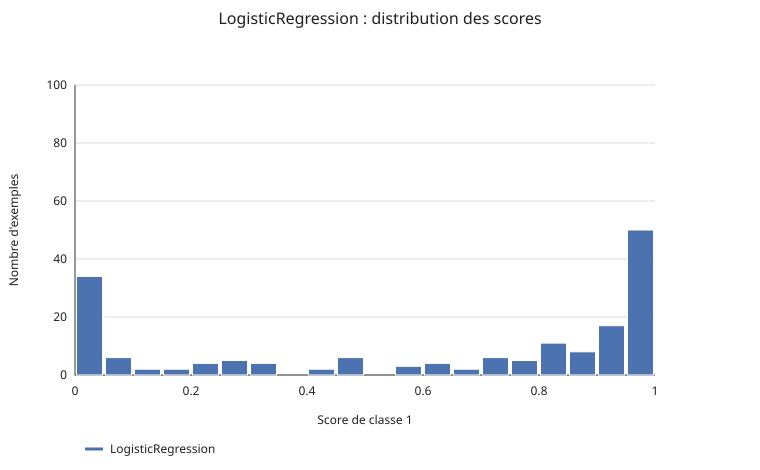

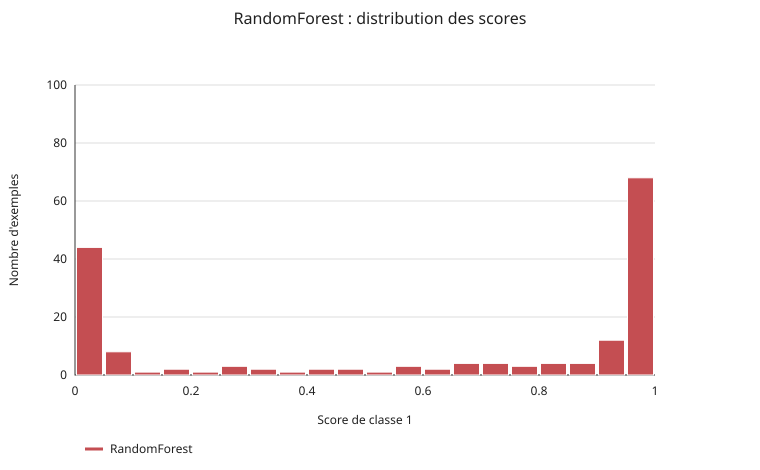

In [65]:
// Un appel ciblé entraîne chaque vrai estimateur, sans déléguer le parcours du carnet.
double[] FitPredict(string model, double[][] trainX, int[] trainY, double[][] testX)
{
    var response = Backend(@"
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
model=(make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
    if cfg['model']=='lr' else RandomForestClassifier(n_estimators=100,random_state=42))
model.fit(np.asarray(cfg['trainX']),np.asarray(cfg['trainY']))
result_json=json.dumps(model.predict_proba(np.asarray(cfg['testX']))[:,1].tolist())
", new { model, trainX, trainY, testX });
    return Doubles(response);
}

var probaLr = FitPredict("lr", XTrain, yTrain, XTest);
var probaRf = FitPredict("rf", XTrain, yTrain, XTest);
Console.WriteLine("Modèle               moyenne  prédits 1  part dans [0.1,0.9]");
foreach (var(name, p)in new[]
{
    ("LogisticRegression", probaLr),
    ("RandomForest", probaRf)
}

)
    Console.WriteLine($"{name, -20} {p.Average():F3}    {p.Count(x => x >= .5), 3}       {p.Count(x => x >= .1 && x <= .9) / (double)p.Length:F3}");
// SVG opaque : titres, unités, légende et graduations restent visibles sur GitHub.
CalibrationSvg SvgChart(string title, string xLabel, string yLabel, (string Name, double[] X, double[] Y, string Color)[] curves, double xMin = 0, double xMax = 1, double yMin = 0, double yMax = 1, bool bars = false)
{
    string E(string s) => SecurityElement.Escape(s) ?? "";
    double PX(double x) => 75 + 580 * (x - xMin) / (xMax - xMin);
    double PY(double y) => 375 - 290 * (y - yMin) / (yMax - yMin);
    var s = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='760' height='470' viewBox='0 0 760 470'><rect width='760' height='470' fill='white'/><g font-family='sans-serif' font-size='12' fill='#202020'>");
    s.Append($"<text x='380' y='24' text-anchor='middle' font-size='16'>{E(title)}</text>");
    for (int k = 0; k <= 5; k++)
    {
        double x = xMin + k * (xMax - xMin) / 5;
        double y = yMin + k * (yMax - yMin) / 5;
        s.Append($"<path d='M75 {PY(y):F3}H655' stroke='#ddd'/><text x='67' y='{PY(y) + 4:F3}' text-anchor='end'>{y:G3}</text>");
        s.Append($"<text x='{PX(x):F3}' y='395' text-anchor='middle'>{x:G3}</text>");
    }

    s.Append("<path d='M75 85V375H655' fill='none' stroke='#333'/>");
    s.Append($"<text x='365' y='424' text-anchor='middle'>{E(xLabel)}</text><text transform='translate(18 230) rotate(-90)' text-anchor='middle'>{E(yLabel)}</text>");
    for (int j = 0; j < curves.Length; j++)
    {
        var c = curves[j];
        var points = Enumerable.Range(0, c.X.Length).Where(i => double.IsFinite(c.X[i]) && double.IsFinite(c.Y[i])).ToArray();
        if (bars)
        {
            foreach (var i in points)
                s.Append($"<rect x='{PX(c.X[i]) - 13:F3}' y='{PY(c.Y[i]):F3}' width='26' height='{375 - PY(c.Y[i]):F3}' fill='{c.Color}' stroke='white'/>");
        }
        else
        {
            var xy = string.Join(" ", points.Select(i => $"{PX(c.X[i]):F3},{PY(c.Y[i]):F3}"));
            s.Append($"<polyline points='{xy}' fill='none' stroke='{c.Color}' stroke-width='2'/>");
            if (c.X.Length <= 20)
                foreach (var i in points)
                    s.Append($"<circle cx='{PX(c.X[i]):F3}' cy='{PY(c.Y[i]):F3}' r='3' fill='{c.Color}'/>");
        }

        s.Append($"<path d='M{85 + j * 210} 449h18' stroke='{c.Color}' stroke-width='3'/><text x='{110 + j * 210}' y='453'>{E(c.Name)}</text>");
    }

    return new CalibrationSvg(s.Append("</g></svg>").ToString());
}

// np.linspace utilise le produit j*(1/n) : conserver les mêmes frontières flottantes.
int Bin(double p, int n) => Enumerable.Range(1, n - 1).Count(j => p >= j * (1.0 / n));
foreach (var(name, p, color)in new[]
{
    ("LogisticRegression", probaLr, "#4c72b0"),
    ("RandomForest", probaRf, "#c44e52")
}

)
{
    var counts = Enumerable.Range(0, 20).Select(b => (double)p.Count(x => Bin(x, 20) == b)).ToArray();
    var centers = Enumerable.Range(0, 20).Select(b => (b + .5) / 20).ToArray();
    display(SvgChart($"{name} : distribution des scores", "Score de classe 1", "Nombre d'exemples", new[] { (name, centers, counts, color) }, yMax: 100, bars: true), "image/svg+xml");
}


## 2. Le reliability diagram : le construire from scratch

L'histogramme ci-dessus montre le symptôme — des moyennes proches, des distributions radicalement différentes : les trois quarts des scores de la forêt vivent sous 0.1 ou au-dessus de 0.9, alors que la régression logistique occupe tout l'intervalle. Mais l'histogramme ne dit pas lequel a **raison**. Le **reliability diagram** (diagramme de fiabilité) tranche. L'idée tient en une phrase : **regrouper les prédictions par niveaux de confiance et confronter chaque groupe à la réalité observée**.

Construction, bin par bin :

1. On découpe [0, 1] en **10 bins** de largeur 0.1 : [0.0, 0.1), [0.1, 0.2), ..., [0.9, 1.0].
2. Pour chaque bin, on calcule la **confiance moyenne** (moyenne des scores prédits des exemples du bin) et la **fréquence observée** (proportion réelle de classe 1 dans ce bin).
3. On trace un point par bin — *(confiance moyenne, fréquence observée)* — plus la diagonale **y = x** de calibration parfaite.

Lecture : un modèle bien calibré aligne ses points sur la diagonale — les patients à qui il promet ~0.7 sont positifs dans ~70 % des cas. Un modèle écrasé vers 0/1 produit des points **au-dessus** de la diagonale à gauche (il dit ~0.02, la réalité est plus élevée) et **en dessous** à droite (il dit ~0.98, la réalité est plus basse) : l'écart visuel **est** le défaut de calibration.

Nous l'implémentons **en C# avec `Bin` et LINQ** pour affecter les scores et calculer les deux moyennes plutôt qu'avec `sklearn.calibration` : pour rendre explicites les agrégations effectuées par cet outil.


bin   LR moyenne  LR fréquence  RF moyenne  RF fréquence


 0      0.023        0.025       0.018        0.135


 1      0.147        0.000       0.160        0.333


 2      0.249        0.444       0.253        0.250


 3      0.316        0.250       0.343        0.333


 4      0.464        0.375       0.450        0.250


 5      0.580        0.667       0.555        0.750


 6      0.640        0.833       0.660        1.000


 7      0.750        0.727       0.749        0.857


 8      0.848        0.947       0.846        0.875


 9      0.966        0.970       0.979        0.925


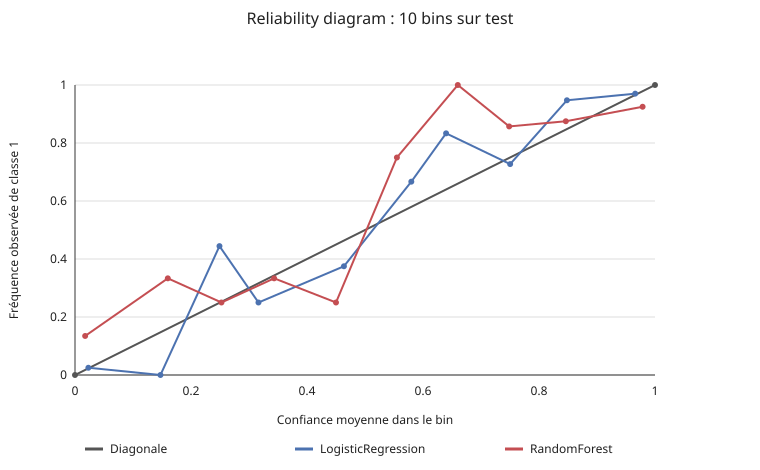

In [66]:
// Un bin vide reste NaN : aucun point fictif à zéro n'est ajouté au diagramme.
(double[] Mean, double[] Frequency, int[] Count) Reliability(int[] y, double[] p, int bins = 10)
{
    var mean = Enumerable.Repeat(double.NaN, bins).ToArray();
    var frequency = Enumerable.Repeat(double.NaN, bins).ToArray();
    var count = new int[bins];
    for (int b = 0; b < bins; b++)
    {
        var indices = Enumerable.Range(0, y.Length).Where(i => Bin(p[i], bins) == b).ToArray();
        count[b] = indices.Length;
        if (count[b] == 0)
            continue;
        mean[b] = indices.Average(i => p[i]);
        frequency[b] = indices.Average(i => y[i]);
    }

    return (mean, frequency, count);
}

var relLr = Reliability(yTest, probaLr);
var relRf = Reliability(yTest, probaRf);
Console.WriteLine("bin   LR moyenne  LR fréquence  RF moyenne  RF fréquence");
for (int b = 0; b < 10; b++)
    Console.WriteLine($"{b, 2}      {relLr.Mean[b]:F3}        {relLr.Frequency[b]:F3}       {relRf.Mean[b]:F3}        {relRf.Frequency[b]:F3}");
display(SvgChart("Reliability diagram : 10 bins sur test", "Confiance moyenne dans le bin", "Fréquence observée de classe 1", new[] { ("Diagonale", new[] { 0.0, 1.0 }, new[] { 0.0, 1.0 }, "#555"), ("LogisticRegression", relLr.Mean, relLr.Frequency, "#4c72b0"), ("RandomForest", relRf.Mean, relRf.Frequency, "#c44e52") }), "image/svg+xml");


## 3. ECE et Brier score : résumer le diagramme en un nombre

Le tableau et le diagramme ci-dessus se lisent d'un coup d'œil : la régression logistique colle grossièrement à la diagonale, tandis que la forêt s'en écarte aux deux extrémités — ses scores ~0.02 cachent une fréquence réelle plus élevée, et son plus gros bin (des scores ~0.98, près d'un patient sur deux du test) promet plus que ce qui s'observe réellement. Mais un diagramme ne tient pas dans un tableau de bord ni dans une comparaison automatisée. Deux chiffres le condensent :

**ECE — Expected Calibration Error.** Pour chaque bin, l'écart vertical du diagramme vaut |confiance moyenne − fréquence observée|. L'ECE agrège ces écarts en une moyenne **pondérée par la taille des bins** :

$$\mathrm{ECE} \;=\; \sum_{b=1}^{10} \frac{n_b}{n}\, \left| \, \text{confiance}_b - \text{fréquence}_b \, \right|$$

Intuition : c'est la distance moyenne au diagramme — l'écart que commet « en moyenne » le modèle entre ce qu'il promet et ce qui arrive. La calibration parfaite en population n’implique pas une ECE empirique nulle sur un échantillon fini. Cette estimation dépend des bins et de l’échantillon ; le seuil 0.03 n’est pas une norme universelle.

**Brier score.** La moyenne des erreurs quadratiques sur les probabilités elles-mêmes :

$$\mathrm{Brier} \;=\; \frac{1}{n} \sum_{i=1}^{n} \left( p_i - y_i \right)^2$$

Le Brier mélange les deux axes : il pénalise à la fois le mauvais ordre (discrimination) et le mauvais quantificatif (calibration) — y compris les écarts **fins**, exemple par exemple, que le binning de l'ECE lisse. On les lit donc ensemble : l’ECE estime un écart de calibration après binning ; le Brier juge la probabilité globale.


In [67]:
// L'ECE pondère par effectif ; le Brier conserve l'information exemple par exemple.
double Ece(int[] y, double[] p, int bins = 10)
{
    var r = Reliability(y, p, bins);
    return Enumerable.Range(0, bins).Where(b => r.Count[b] > 0).Sum(b => r.Count[b] / (double)y.Length * Math.Abs(r.Mean[b] - r.Frequency[b]));
}

double Brier(int[] y, double[] p) => Enumerable.Range(0, y.Length).Average(i => Math.Pow(p[i] - y[i], 2));
Console.WriteLine("Modèle                  ECE    Brier");
foreach (var(name, p)in new[]
{
    ("LogisticRegression", probaLr),
    ("RandomForest", probaRf)
}

)
    Console.WriteLine($"{name, -20} {Ece(yTest, p):F4} {Brier(yTest, p):F4}");


Modèle                  ECE    Brier


LogisticRegression   0.0424 0.0765


RandomForest         0.0909 0.1107


### Exercice 1 : mesurer l'incertitude de l'ECE avec un bootstrap

Le tableau ci-dessus chiffre le contraste : l'ECE de la forêt aléatoire est environ le double de celle de la régression logistique. Mais chaque ECE est calculée sur **un seul** ensemble de test de 171 patients — quel intervalle de confiance lui donner ?

À vous de jouer : rééchantillonnez le test **avec remise** (*bootstrap*) et recalculez l'ECE à chaque tirage pour obtenir un intervalle à 95 %.

Indices :
- `# Étape 1` : utiliser les 100 rééchantillonnages de `bootstrapIndices`, générées avec remise par NumPy `default_rng(42)` ; chacune contient `yTest.Length` indices.
- `# Étape 2` : sélectionner les couples `yTest[i]` / `probaRf[i]` pour chaque ligne, appeler `Ece` et conserver les 100 résultats.
- `# Étape 3` : trier les 100 ECE, puis interpoler linéairement aux positions `0.025*(n-1)` et `0.975*(n-1)` pour les deux bornes.
- Lecture : l’intervalle décrit la variabilité de l’ECE du RF. Le comparer à une ECE LR ponctuelle n’est pas un test apparié de leur différence ; un tel test devrait rééchantillonner les deux scores ensemble.


Le contrat vérifie la trace seedée complète à une précision de 1e-8, et que les bornes correspondent aux percentiles de la liste soumise. Il reste un contrôle fini, pas une preuve pour tout programme.


In [68]:
// Empreinte ordonnée de toutes les valeurs quantifiées à 1e-8, compatible avec NumPy rint.
string TraceDigest(IEnumerable<double> values)
{
    var text = string.Join(",", values.Select(v => ((long)Math.Round(v * 1e8, MidpointRounding.ToEven)).ToString(CultureInfo.InvariantCulture)));
    return Convert.ToHexString(System.Security.Cryptography.SHA256.HashData(Encoding.UTF8.GetBytes(text))).ToLowerInvariant();
}

double TraceQuantile(double[] values, double q)
{
    var x = values.OrderBy(v => v).ToArray();
    double position = q * (x.Length - 1);
    int k = (int)position;
    return x[k] + (position - k) * (x[Math.Min(k + 1, x.Length - 1)] - x[k]);
}

// Exercice 1 : calculer 100 ECE et les percentiles 2.5/97.5 (interpolation linéaire).
// Les indices viennent du même PCG64 NumPy que le Python, pas de métriques Python.
var bootData = Backend(@"rng=np.random.default_rng(42)
result_json=json.dumps(rng.integers(0,cfg['n'],(100,cfg['n'])).tolist())", new { n = yTest.Length });
var bootstrapIndices = bootData.EnumerateArray().Select(Ints).ToArray();
double[] eceEchantillons = null; // TODO : Ece sur les couples (y,p) rééchantillonnés.
double[] bornes = null; // TODO : deux percentiles sur les 100 ECE, après tri.
Console.WriteLine($"Exercice 1 à compléter : ECE RF={Ece(yTest, probaRf):F4}, IC95%={(bornes == null ? "non renseigné" : string.Join(", ", bornes))}");
void Require(bool ok, string message)
{
    if (!ok)
        throw new ArgumentException(message);
}

// Ce contrat fini repère les valeurs constantes et les indices mal alignés ; il ne prouve pas toute solution.
if (eceEchantillons != null || bornes != null)
{
    Require(eceEchantillons != null && eceEchantillons.Length == 100 && eceEchantillons.All(double.IsFinite), "100 ECE finies requises");
    Require(bornes != null && bornes.Length == 2 && bornes.All(double.IsFinite), "Deux bornes finies requises");
    Require(Math.Abs(eceEchantillons[0] - 0.09608187134502924) < 1e-10, "Tirage 0 incorrect");
    Require(Math.Abs(eceEchantillons[1] - 0.09497076023391814) < 1e-10, "Tirage 1 incorrect");
    Require(Math.Abs(eceEchantillons[7] - 0.12339181286549712) < 1e-10, "Tirage 7 incorrect");
    Require(Math.Abs(eceEchantillons[19] - 0.13017543859649125) < 1e-10, "Tirage 19 incorrect");
    Require(Math.Abs(eceEchantillons[37] - 0.12421052631578937) < 1e-10, "Tirage 37 incorrect");
    Require(Math.Abs(eceEchantillons[55] - 0.11233918128654972) < 1e-10, "Tirage 55 incorrect");
    Require(Math.Abs(eceEchantillons[73] - 0.11087719298245619) < 1e-10, "Tirage 73 incorrect");
    Require(Math.Abs(eceEchantillons[99] - 0.10105263157894735) < 1e-10, "Tirage 99 incorrect");
    Require(Math.Abs(eceEchantillons.Sum() - 10.836374269005846) < 1e-9, "Somme incorrecte");
    Require(Math.Abs(bornes[0] - 0.06119152046783628) < 1e-10, "Percentile incorrect");
    Require(Math.Abs(bornes[1] - 0.1577295321637426) < 1e-10, "Percentile incorrect");
    Require(TraceDigest(eceEchantillons) == "7229e501a5b4a1152948ffa85dad4dddc9285d8347c59da51b4df27c5336ae1d", "Trace bootstrap incorrecte");
    Require(Math.Abs(bornes[0] - TraceQuantile(eceEchantillons, .025)) < 1e-12 && Math.Abs(bornes[1] - TraceQuantile(eceEchantillons, .975)) < 1e-12, "Bornes incohérentes avec les données soumises");
    Console.WriteLine("Contrat bootstrap satisfait ; discuter la portée statistique séparément.");
}


Exercice 1 à compléter : ECE RF=0.0909, IC95%=non renseigné


## 4. Platt scaling : recalibrer avec… une régression logistique

Diagnostic posé, passons au traitement. L'idée la plus simple : apprendre une **transformation** qui remappe le score défectueux vers une probabilité correcte. On ajuste une régression logistique (notebook 2.3) dont l'**unique variable d'entrée est le score du modèle à corriger** — pas les mesures d'origine :

$$p_{\text{calibrée}} \;=\; \sigma\!\left(a \cdot \text{score} + b\right)$$

C'est le **Platt scaling** (Platt, 1999). Si le modèle est écrasé vers les extrêmes, la sigmoïde apprise ramène ses scores trop confiants vers leurs fréquences réelles. Faites le lien avec 2.3 : c'est exactement le même modèle, appliqué à une seule feature bien choisie — le score lui-même.

> **Règle d'or (et on l'applique).** Le calibrateur ne doit **jamais** être ajusté sur les données qui servent à l'évaluer. Nous l'ajustons donc sur les scores **out-of-fold** de l'entraînement : pour chaque patient du train, le score d'une forêt qui ne l'a **pas** vu (`cross_val_predict` à 5 plis) — un protocole à calibrateur unique ajusté sur tous les scores OOF. Ce n’est pas exactement le protocole par défaut de `CalibratedClassifierCV`, qui peut agréger des estimateurs/calibrateurs par pli et emploie une autre procédure d’ajustement sigmoïde. Le test reste vierge jusqu'à l'évaluation finale.


In [69]:
// C# orchestre les cinq fits : aucune observation de validation n'entre dans son entraînement.
var scoresOof = new double[yTrain.Length];
var coverage = new int[yTrain.Length];
foreach (var fold in dataset.GetProperty("folds").EnumerateArray())
{
    var train = Ints(fold.GetProperty("train"));
    var valid = Ints(fold.GetProperty("valid"));
    if (train.Intersect(valid).Any())
        throw new InvalidOperationException("Fuite entre plis");
    var predicted = FitPredict("rf", train.Select(i => XTrain[i]).ToArray(), train.Select(i => yTrain[i]).ToArray(), valid.Select(i => XTrain[i]).ToArray());
    for (int j = 0; j < valid.Length; j++)
    {
        scoresOof[valid[j]] = predicted[j];
        coverage[valid[j]]++;
    }
}

if (coverage.Any(n => n != 1))
    throw new InvalidOperationException("Couverture OOF incorrecte");
var grid = Enumerable.Range(0, 200).Select(i => i / 199.0).ToArray();
var plattFit = Backend(@"
from sklearn.linear_model import LogisticRegression
model=LogisticRegression().fit(np.asarray(cfg['scores']).reshape(-1,1),np.asarray(cfg['labels']))
result_json=json.dumps(dict(a=float(model.coef_[0,0]),b=float(model.intercept_[0]),
    test=model.predict_proba(np.asarray(cfg['test']).reshape(-1,1))[:,1].tolist(),
    grid=model.predict_proba(np.asarray(cfg['grid']).reshape(-1,1))[:,1].tolist()))
", new { scores = scoresOof, labels = yTrain, test = probaRf, grid });
var probaPlatt = Doubles(plattFit.GetProperty("test"));
var gridPlatt = Doubles(plattFit.GetProperty("grid"));
double a = plattFit.GetProperty("a").GetDouble(), bPlatt = plattFit.GetProperty("b").GetDouble();
Console.WriteLine($"Sigmoïde apprise : p = sigmoid({a:F3} * score + ({bPlatt:F3}))");
Console.WriteLine($"Pente positive : {a > 0} ; OOF : {coverage.Length} scores, cinq plis");
Console.WriteLine($"ECE RF brut : {Ece(yTest, probaRf):F4} ; RF + Platt : {Ece(yTest, probaPlatt):F4}");


Sigmoïde apprise : p = sigmoid(4.998 * score + (-2.434))


Pente positive : True ; OOF : 398 scores, cinq plis


ECE RF brut : 0.0909 ; RF + Platt : 0.0552


## 5. Régression isotonique : la version non paramétrique

Le Platt scaling impose une **forme** (une sigmoïde, deux paramètres). La **régression isotonique** lève cette contrainte : elle apprend la fonction **non décroissante** ajustée aux observations (avec interpolation linéaire entre les nœuds dans `IsotonicRegression.predict`) qui colle au mieux aux données (Zadrozny & Elkan, 2002). Plus flexible, elle a besoin de **plus de données** pour ne pas apprendre le bruit — ici, la fonction s’ajuste sur 398 scores out-of-fold, et une grande masse d'entre eux est écrasée dans les mêmes bins : c'est le régime défavorable à une méthode non paramétrique. Regardons ce que ça donne — la théorie ne promet pas que « plus flexible » gagne toujours.

La sigmoïde de Platt est strictement croissante **si sa pente apprise est positive**, ce qui sera vérifié ici. L’isotonique est non décroissante : des scores distincts peuvent devenir égaux. Une transformation monotone ne prouve pas la calibration hors échantillon. Visualisons la carte de calibration apprise par chaque méthode.


ECE RF brut : 0.0909


ECE RF + Platt : 0.0552


ECE RF + isotonique : 0.0941


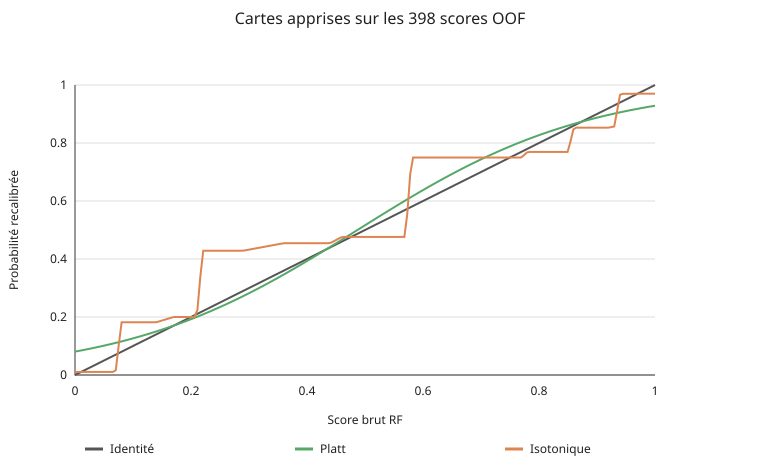

In [70]:
// IsotonicRegression réel : le modèle interpole entre nœuds et clippe hors du domaine.
var isoFit = Backend(@"
from sklearn.isotonic import IsotonicRegression
model=IsotonicRegression(out_of_bounds='clip').fit(cfg['scores'],cfg['labels'])
result_json=json.dumps(dict(test=np.clip(model.predict(cfg['test']),0,1).tolist(),
    grid=np.clip(model.predict(cfg['grid']),0,1).tolist()))
", new { scores = scoresOof, labels = yTrain, test = probaRf, grid });
var probaIso = Doubles(isoFit.GetProperty("test"));
var gridIso = Doubles(isoFit.GetProperty("grid"));
Console.WriteLine($"ECE RF brut : {Ece(yTest, probaRf):F4}");
Console.WriteLine($"ECE RF + Platt : {Ece(yTest, probaPlatt):F4}");
Console.WriteLine($"ECE RF + isotonique : {Ece(yTest, probaIso):F4}");
display(SvgChart("Cartes apprises sur les 398 scores OOF", "Score brut RF", "Probabilité recalibrée", new[] { ("Identité", grid, grid, "#555"), ("Platt", grid, gridPlatt, "#55a868"), ("Isotonique", grid, gridIso, "#dd8452") }), "image/svg+xml");


## 6. Ce que la calibration conserve et ce qu’elle peut modifier

Un mot d'abord sur le résultat de la section 5 : la sigmoïde contrainte du Platt réduit l'ECE de 39 % (0.091 → 0.055), tandis que la fonction monotone isotonique stagne (0.094) — cette réalisation est compatible avec un compromis biais-variance défavorable, mais ne démontre pas à elle seule un surapprentissage. Les deux calibrateurs sont ajustés sur les **mêmes** 398 scores out-of-fold (la cellule du Platt définit `scoresOof`, celle de l'isotonique s'ajuste sur ce même tableau) : la hiérarchie compare donc deux formes — sigmoïde contrainte contre fonction monotone souple — et non deux protocoles d'ajustement. Dix fois plus de données pourraient modifier la comparaison, sans garantir un gagnant ; ici, la contrainte gagne sur l’ECE mesurée. C'est une leçon générale : le calibrateur, lui aussi, est un modèle, avec son propre compromis biais-variance.

Regardez maintenant la figure ci-dessus : Platt préserve strictement l’ordre ici car sa pente est positive ; l’isotonique préserve l’ordre faible, avec des ex æquo possibles. Il s’agit toujours du score de classe 1 (bénin). Trois corollaires à vérifier :

1. **L’AUC est préservée par Platt ici** : la pente positive rend la sigmoïde apprise strictement croissante, elle ne dépend que de l'ordre, pas des valeurs — l'AUC du RF brut et du RF calibré Platt doivent coïncider. L’isotonique, elle, peut créer des **plateaux** : ils introduisent des **égalités** (deux scores distincts ramenés à la même valeur), ce qui peut augmenter ou diminuer l’AUC selon les paires réunies.
2. **La discrimination dépend de la transformation** : une transformation strictement croissante conserve l’AUC, mais les ex æquo isotoniques peuvent la modifier. Apprendre un calibrateur ne garantit pas que les probabilités seront exactes sur de nouvelles données.
3. **Le seuil 0.5 calibré correspond à un seuil différent sur le score brut** : $p_{\text{cal}} \geq 0.5 \Leftrightarrow \text{score} \geq -b/a$ pour une pente $a>0$. Si ce nouveau seuil tombe dans une zone presque vide de l'histogramme de la section 1, **aucun** patient ne change de prédiction au seuil 0.5 — mais c'est une coïncidence empirique, pas une garantie : le seuil de référence sur le score brut, lui, a bel et bien bougé.

Le message : **calibrer ne « répare » pas un modèle** — cela apprend une autre échelle probabiliste dont la fiabilité reste à évaluer. Un modèle mal calibré mais bien ordonnant était déjà un bon *trieur* de patients ; il était un mauvais *pronostiqueur*.


In [71]:
// L'AUC est la probabilité de bon classement d'une paire, avec un demi-point par égalité.
double Auc(int[] y, double[] p)
{
    var pos = Enumerable.Range(0, y.Length).Where(i => y[i] == 1).ToArray();
    var neg = Enumerable.Range(0, y.Length).Where(i => y[i] == 0).ToArray();
    return pos.Sum((int i) => neg.Sum((int j) => p[i] > p[j] ? 1.0 : p[i] == p[j] ? .5 : 0)) / (pos.Length * (double)neg.Length);
}

Console.WriteLine($"AUC RF brut : {Auc(yTest, probaRf):F4}");
Console.WriteLine($"AUC RF + Platt : {Auc(yTest, probaPlatt):F4}");
Console.WriteLine($"AUC RF + isotonique : {Auc(yTest, probaIso):F4}");
foreach (var(name, p)in new[]
{
    ("Platt", probaPlatt),
    ("isotonique", probaIso)
}

)
    Console.WriteLine($"Décisions basculant à 0.5, brut -> {name} : {Enumerable.Range(0, yTest.Length).Count(i => (probaRf[i] >= .5) != (p[i] >= .5))}");


AUC RF brut : 0.9129


AUC RF + Platt : 0.9129


AUC RF + isotonique : 0.9000


Décisions basculant à 0.5, brut -> Platt : 0


Décisions basculant à 0.5, brut -> isotonique : 3



(6,47): info CS9236: La compilation nécessite la liaison de l’expression lambda au moins 100 fois. Envisagez de déclarer l’expression lambda avec des types de paramètre explicites ou, si l’appel de méthode conteneur est générique, utilisez des arguments de type explicite.



### Exercice 2 : la température, le Platt scaling des réseaux de neurones

Les réseaux de neurones produisent des **logits** $z$ avant le softmax, et les logits des réseaux modernes sont notoirement **surconfiants**. Le **temperature scaling** (Guo et al., 2017) divise les logits par une température $T$ avant le softmax :

$$\text{softmax}(z / T)$$

- $T > 1$ : le softmax **ramollit** — les probabilités quittent les extrêmes (réseau surconfiant).
- $T < 1$ : le softmax **durcit** — probabilités plus tranchées (réseau sous-confiant).

C'est un Platt scaling à un paramètre (pente $1/T$, pas d'ordonnée à l'origine) appliqué aux logits. Le $T$ optimal est celui qui minimise la log-vraisemblance négative (NLL) sur un jeu de validation.

Le code ci-dessous simule un réseau **surconfiant** : les labels de validation ont été générés avec une vraie température de 2 (les logits sont deux fois trop grands pour la réalité). À vous de retrouver $T$.

Indices :
- `# Étape 1` : probabilité = `1 / (1 + Math.Exp(-logit / T))` (le softmax binaire est une sigmoïde).
- `# Étape 2` : NLL = la moyenne de `-y*Math.Log(p)-(1-y)*Math.Log(1-p)`, en protégeant les logs (`Math.Clamp(p, 1e-12, 1-1e-12)`).
- `# Étape 3` : balayer `T` sur les 91 valeurs `.5 + i*.05`, pour `i=0..90` et garder le minimisateur.


In [72]:
// Exercice 2 : vrais tirages NumPy seedés, NLL et recherche de température à coder en C#.
var temperatureData = Backend(@"rng=np.random.default_rng(0)
z=rng.normal(1.5,1.,500)
y=(rng.random(500)<1/(1+np.exp(-z/2))).astype(int)
result_json=json.dumps(dict(z=z.tolist(),y=y.tolist()))", new { });
var logitsReseau = Doubles(temperatureData.GetProperty("z"));
var yVal = Ints(temperatureData.GetProperty("y"));
double? NllTemperature(double temperature, double[] logits, int[] labels)
{
    // TODO : sigmoid(logit/T), clip [1e-12,1-1e-12], puis NLL moyenne.
    return null;
}

double? tOptimal = null; // TODO : minimum sur les 91 températures de 0.5 à 5.
Console.WriteLine($"Exercice 2 à compléter : T optimal = {tOptimal?.ToString() ?? "non renseigné"} (générateur : 2)");
// Les fixtures comportent deux classes, des logits nuls et des valeurs extrêmes.
if (tOptimal.HasValue || NllTemperature(1, new[] { 0.0, 0.0 }, new[] { 0, 1 }).HasValue)
{
    {
        var v = NllTemperature(1.0, new[] { 0.0, 0.0 }, new[] { 0, 1 });
        Require(v.HasValue && double.IsFinite(v.Value) && Math.Abs(v.Value - 0.6931471805599453) < 1e-8, "NLL de fixture incorrecte");
    }

    {
        var v = NllTemperature(2.0, new[] { -2.0, 2.0 }, new[] { 0, 1 });
        Require(v.HasValue && double.IsFinite(v.Value) && Math.Abs(v.Value - 0.3132616875182228) < 1e-8, "NLL de fixture incorrecte");
    }

    {
        var v = NllTemperature(0.5, new[] { 1.0, -1.0, 0.0 }, new[] { 0, 1, 1 });
        Require(v.HasValue && double.IsFinite(v.Value) && Math.Abs(v.Value - 1.64900106754863) < 1e-8, "NLL de fixture incorrecte");
    }

    {
        var v = NllTemperature(1.0, new[] { 1000.0, -1000.0 }, new[] { 0, 1 });
        Require(v.HasValue && double.IsFinite(v.Value) && Math.Abs(v.Value - 27.631032176910953) < 1e-8, "NLL de fixture incorrecte");
    }

    var temperatures = Enumerable.Range(0, 91).Select(i => .5 + i * .05).ToArray();
    var losses = temperatures.Select(t => NllTemperature(t, logitsReseau, yVal)).ToArray();
    Require(losses.All(v => v.HasValue && double.IsFinite(v.Value)), "91 NLL finies requises");
    Require(Math.Abs(losses.Sum(v => v.Value) - 57.072155043762486) < 1e-8, "Somme des 91 NLL incorrecte");
    Require(tOptimal.HasValue && double.IsFinite(tOptimal.Value) && Math.Abs(tOptimal.Value - 1.8) < 1e-10, "Minimum de grille incorrect");
    Require(Math.Abs(losses.Min(v => v.Value) - 0.5953277118686279) < 1e-10, "Valeur minimale incorrecte");
    Require(TraceDigest(losses.Select(v => v.Value)) == "53a7b1e7aaabd5b2511427a9b30b1e6ea749421e25105395243bec12aa1e669a", "Trace NLL incorrecte");
    int bestIndex = Enumerable.Range(0, losses.Length).OrderBy(i => losses[i].Value).First();
    Require(Math.Abs(tOptimal.Value - temperatures[bestIndex]) < 1e-12, "Optimum incohérent avec la courbe soumise");
    Console.WriteLine("Contrat température satisfait ; l’estimation sur 500 labels n’est pas le paramètre générateur exact.");
}


Exercice 2 à compléter : T optimal = non renseigné (générateur : 2)


## 7. Usage en aval : espérance de gain avec probabilités calibrées vs brutes

Pourquoi tant d'effort ? Parce qu'en aval, on ne consomme presque jamais un score seul : on le branche dans un **calcul de décision**. Mini-cas de décision **fictif**, sans interprétation thérapeutique (la classe 1 du jeu signifie bénin) : une action coûte **100**, rapporte **200** si elle concerne un exemple de classe 1, et rien sinon. L'espérance de gain en appliquant l’action à un exemple de probabilité $p$ :

$$\mathrm{EV}(p) \;=\; 200 \cdot p - 100$$

On choisit l’action si $\mathrm{EV} > 0$, c'est-à-dire $p > 0.5$. Le point clé : l'espérance dépend **linéairement** de $p$ — dans son bin de scores ~0.98, la forêt annonce 0.979 là où la fréquence observée est 0.925 : elle promet EV = +96 quand le gain moyen empirique de ce bin vaut environ +85. Le classement reste identique pour Platt à pente positive ; l’écart au **gain empirique du bin** décrit ce test, sans révéler la probabilité vraie de chaque personne : au voisinage du seuil, c'est l'inverse — la forêt sous-estime, comme la comparaison ci-dessous le montre.

Comparons, sur les 10 patients de test dont le score RF est le plus proche de 0.5 (la zone où la décision se joue), l'espérance calculée avec les probabilités brutes vs recalibrées par Platt.


In [73]:
// Dix scores proches de 0.5 ; le tri stable départage les ex aequo par indice.
var border = Enumerable.Range(0, yTest.Length).OrderBy(i => Math.Abs(probaRf[i] - .5)).ThenBy(i => i).Take(10).ToArray();
Console.WriteLine("RF brut   Platt  classe  EV brute  EV Platt");
foreach (int i in border)
    Console.WriteLine($"{probaRf[i]:F3}     {probaPlatt[i]:F3}    {yTest[i]}       {200 * probaRf[i] - 100, 6:F1}    {200 * probaPlatt[i] - 100, 6:F1}");
Console.WriteLine($"EV moyenne prédite brute : {border.Average(i => 200 * probaRf[i] - 100):F1}");
Console.WriteLine($"EV moyenne prédite Platt : {border.Average(i => 200 * probaPlatt[i] - 100):F1}");
Console.WriteLine("Ces espérances prédites ne constituent pas des gains réalisés.");


RF brut   Platt  classe  EV brute  EV Platt


0.480     0.491    0         -4.0      -1.7


0.530     0.554    0          6.0      10.7


0.460     0.466    0         -8.0      -6.7


0.550     0.578    1         10.0      15.6


0.440     0.442    1        -12.0     -11.7


... (4 outputs left out)

0.610     0.649    1         22.0      29.8


EV moyenne prédite brute : 4.8


EV moyenne prédite Platt : 9.0


Ces espérances prédites ne constituent pas des gains réalisés.


### Exercice 3 (capstone) : le seuil qui maximise le gain observé (analyse rétrospective)

La cellule précédente calcule l'espérance *si l'on traite tous* les patients borderline. Les deux espérances prédites diffèrent (+4.8 brut contre +9.0 recalibré). Ce changement de prédiction n’est pas un gain réalisé ni une preuve de sous-confiance : il faudrait le confronter à des résultats observés indépendants. L'exercice est de choisir **qui traiter** : balayer le seuil de décision $s$ (traiter si $p \geq s$) et trouver celui qui maximise le gain **total observé** sur l’ensemble de test, avec les probabilités **calibrées** (Platt). C'est la généralisation calculée de la section 7 du notebook 2.5, où le seuil était posé à la main selon le coût des erreurs.

Indices :
- `# Étape 1` : pour un seuil `s`, les décisions sont `probas[i] >= s`.
- `# Étape 2` : gain = `+(benefice - cout)` si traité et `y == 1`, `-cout` si traité et `y == 0`, `0` sinon (agréger les gains avec LINQ).
- `# Étape 3` : balayer `seuils` avec `probaPlatt` et `yTest`, garder le `s` du gain total maximal.
- Question bonus : le seuil optimal diffère-t-il de celui obtenu avec les probabilités brutes ? (Repensez à la section 6 : l'ordre est préservé… mais le seuil 0.5 calibré correspond à un autre seuil sur le score brut.)


Choisir le seuil sur le test donne une estimation optimiste : ce capstone est un diagnostic rétrospectif. Pour une décision prospective, sélectionner le seuil sur validation, puis évaluer une seule fois sur un test indépendant.


In [74]:
// Exercice 3 : gain observé, pas simple somme des espérances prédites.
var seuils = Enumerable.Range(1, 99).Select(i => i * .01).ToArray();
double? GainTotal(double seuil, double[] probas, int[] labels, double cout = 100, double benefice = 200)
{
    // TODO : décision p >= seuil ; gain benefice*y-cout uniquement si décision positive.
    return null;
}

double? meilleurSeuil = null; // TODO : premier maximiseur sur les 99 seuils.
Console.WriteLine($"Exercice 3 à compléter : seuil = {meilleurSeuil?.ToString() ?? "non renseigné"}");
// Des fixtures séparent la convention >=, les faux positifs et les paramètres économiques.
if (meilleurSeuil.HasValue || GainTotal(.5, new[] { .2, .5, .8 }, new[] { 0, 1, 0 }).HasValue)
{
    foreach (var(s, y, cost, benefit, expected)in new[]
    {
        (.5, new[] { 0, 1, 0 }, 100.0, 200.0, 0.0),
        (.8, new[] { 0, 1, 0 }, 100.0, 200.0, -100.0),
        (.5, new[] { 0, 1, 1 }, 20.0, 90.0, 140.0),
        (.9, new[] { 0, 1, 1 }, 20.0, 90.0, 0.0)
    }

    )
    {
        var got = GainTotal(s, new[] { .2, .5, .8 }, y, cost, benefit);
        Require(got.HasValue && double.IsFinite(got.Value) && Math.Abs(got.Value - expected) < 1e-8, "Gain de fixture incorrect");
    }

    var gains = seuils.Select(s => GainTotal(s, probaPlatt, yTest)).ToArray();
    Require(gains.All(v => v.HasValue && double.IsFinite(v.Value)), "99 gains finis requis");
    Require(Math.Abs(gains.Sum(v => v.Value) - 715100) < 1e-8 && Math.Abs(gains.Max(v => v.Value) - 8800) < 1e-8, "Grille de gains incorrecte");
    Require(meilleurSeuil.HasValue && double.IsFinite(meilleurSeuil.Value) && Math.Abs(meilleurSeuil.Value - 0.56) < 1e-10, "Seuil incorrect");
    Require(TraceDigest(gains.Select(v => v.Value)) == "c07b985b27cd2043f8308ff5a8165542858e63457259f3966fb4476f13d3f547", "Trace des 99 gains incorrecte");
    int bestGain = Enumerable.Range(0, gains.Length).OrderByDescending(i => gains[i].Value).First();
    Require(Math.Abs(meilleurSeuil.Value - seuils[bestGain]) < 1e-12, "Seuil incohérent avec le premier maximum");
    Console.WriteLine("Contrat gain satisfait ; sélection sur test, résultat rétrospectif optimiste.");
}


Exercice 3 à compléter : seuil = non renseigné


## Synthèse et transition

Trois leçons à retenir :

1. **Bien calibré ≠ bon classement.** L'AUC ne voit que l'ordre des exemples ; la calibration demande en plus que le score se comporte comme une fréquence. Une régression logistique sort souvent bien calibrée ; une forêt aléatoire concentre ses scores aux bords (ici 76 % hors de [0.1, 0.9]) tout en se trompant sur leur valeur — elle **sous-estime** sa confiance dans la zone médiane et la **sur-estime** dans son bin le plus peuplé. Le reliability diagram expose l'écart ; l'ECE et le Brier le chiffrent.
2. **La monotonie a des conditions.** Platt conserve l’AUC si sa pente est positive ; les ex æquo isotoniques peuvent la modifier. Le nombre de décisions qui basculent dépend des scores et du seuil, pas seulement de la monotonie.
3. **Une probabilité mal calibrée peut biaiser une espérance de gain.** Dès qu'une espérance de gain, un prix ou un niveau de risque se calcule à partir du score, l'écart de calibration se propage tel quel dans le chiffre présenté au décideur, et son **sens suit celui de l'écart** : au voisinage du seuil les espérances prédites passent de +4.8 à +9.0 sans démontrer un gain réel, tandis que le bin ~0.98 donne environ +96 prédits contre +85 empiriques.

Transition : avec la classification, ses métriques (2.5) et ses probabilités calibrées, nous avons épuisé le cas « données étiquetées ». Le notebook suivant (`2.6-Clustering-KMeans-PCA`) quitte le supervisé pour le **non supervisé** : regrouper des exemples sans étiquettes (**KMeans**) et compresser les variables (**PCA**).


## References

1. Niculescu-Mizil, A. & Caruana, R. (2005). *Predicting Good Probabilities With Supervised Learning*. ICML 2005. — La calibration par famille de modèles : méthodes à marge maximale poussées loin de 0 et 1, Naive Bayes vers 0 et 1, ensembles par moyennage tirés vers le milieu ; Platt scaling et régression isotonique.
2. Platt, J. (1999). *Probabilistic Outputs for Support Vector Machines and Comparisons to Regularized Likelihood Methods*. Advances in Large Margin Classifiers. — Le Platt scaling : une sigmoïde apprise sur les scores.
3. Zadrozny, B. & Elkan, C. (2002). *Transforming Classifier Scores into Accurate Multiclass Probability Estimates*. KDD 2002. — La régression isotonique comme calibration non paramétrique.
4. Guo, C., Pleiss, G., Sun, Y. & Weinberger, K. (2017). *On Calibration of Modern Neural Networks*. ICML 2017. — Reliability diagrams, ECE et temperature scaling pour les réseaux de neurones.
5. Brier, G. W. (1950). *Verification of Forecasts Expressed in Terms of Probability*. Monthly Weather Review 78(1):1-3. — Le score de Brier, venu de la prévision météorologique.


Ces références et leurs descriptions sont reprises du notebook Python versionné ; cette campagne de portage ne revendique pas une nouvelle lecture indépendante des publications.


## À retenir

La calibration compare probabilité annoncée et fréquence observée ; elle complète la discrimination. Le recalibrage doit être appris hors des observations servant à son évaluation : Platt impose une sigmoïde, l’isotonique une fonction monotone plus souple.

## Vérifiez votre compréhension

1. Une AUC élevée garantit-elle des probabilités calibrées ?

<details><summary>Réponse 1</summary>

Non : le classement peut être bon même si les scores surestiment ou sous-estiment les fréquences.

</details>

2. Que résume l’ECE ?

<details><summary>Réponse 2</summary>

Une moyenne pondérée des écarts entre score moyen et fréquence observée dans les intervalles choisis ; elle dépend du regroupement.

</details>

3. Pourquoi utiliser des scores hors pli pour le recalibrage ?

<details><summary>Réponse 3</summary>

Ils limitent la fuite liée au réemploi de scores produits sur les observations ayant servi à ajuster le modèle.

</details>

4. Pourquoi l’isotonique peut-elle modifier l’AUC ?

<details><summary>Réponse 4</summary>

Ses plateaux peuvent créer des ex æquo même si la transformation est monotone.

</details>

## Pour aller plus loin

[Validation et métriques](2.5-Biais-Variance-CV-ROC.ipynb) rappelle le rôle de l’AUC et des seuils.
